# **CELLULE 1. Montage de drive**





In [ ]:
# Importation du module os pour interagir avec le système d'exploitation (gestion des chemins de fichiers)
import os
from google.colab import drive

# Monter Google Drive pour accéder à vos fichiers
# Si Drive est déjà monté, cette ligne affichera un message l'indiquant.
drive.mount('/content/drive')

# Définir le chemin vers le répertoire principal de vos datasets dans Google Drive
# Assurez-vous que ce chemin est correct et mène au dossier qui contient vos différents datasets.
# Exemple : '/content/drive/MyDrive/Votre_Dossier_Datasets'
datasets_base_path = '/content/drive/MyDrive/DataSets' # Remplacez par le chemin réel de votre dossier principal dans Drive

# Vérifier si le chemin existe et lister les éléments à l'intérieur
if os.path.exists(datasets_base_path):
    print(f"Contenu du répertoire '{datasets_base_path}':")
    # Lister uniquement les dossiers pour identifier les potentiels datasets
    dataset_folders_in_drive = [item for item in os.listdir(datasets_base_path) if os.path.isdir(os.path.join(datasets_base_path, item))]
    if dataset_folders_in_drive :
        print("Dossiers trouvés (potentiels datasets) :")
        for folder in dataset_folders_in_drive:
            print(f"- {folder}")
    else:
        print("Aucun dossier trouvé dans ce répertoire.")
else:
    print(f"Erreur : Le chemin '{datasets_base_path}' n'existe pas.")
    print("Veuillez vérifier le chemin spécifié vers vos datasets dans Google Drive.")

# Stocker le chemin pour les étapes futures
# Assurez-vous que la variable `datasets_base_path` est correctement définie ici.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Contenu du répertoire '/content/drive/MyDrive/DataSets':
Dossiers trouvés (potentiels datasets) :
- valid
- train
- test


# **CELLULE 2. Analyser la structure des datasets et identifier les classes**

---



`Cette cellule de code va parcourir chaque dossier identifié comme un dataset, analyser sa structure (dossiers de classes directs ou structure train/valid/test) et identifier les noms des classes présentes.`

In [ ]:
# Fonction pour analyser la structure d'un dataset et identifier les noms de classes
def analyze_dataset_structure_and_identify_classes(dataset_path, image_extensions):
    """
    Analyse la structure d'un dataset et identifie les noms des classes présentes.

    Args:
        dataset_path (str): Le chemin du répertoire du dataset.
        image_extensions (list): Une liste d'extensions de fichiers image à rechercher pour identifier les dossiers potentiels de classes.

    Returns:
        tuple: Un tuple contenant:
               - set: Un ensemble des noms de classes détectés.
               - bool: True si la structure train/valid/test est détectée, False sinon.
    """
    possible_classes = set()
    is_split_structure = False

    if not os.path.isdir(dataset_path):
        print(f"  Attention: Le chemin n'est pas un répertoire valide: {dataset_path}")
        return possible_classes, is_split_structure

    # Vérifier la présence des dossiers train/test/valid au premier niveau
    items_in_dataset = [os.path.join(dataset_path, item) for item in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, item))]
    folder_names_in_dataset = [os.path.basename(item).lower() for item in items_in_dataset]

    if all(split_name in folder_names_in_dataset for split_name in ['train', 'valid', 'test']):
        is_split_structure = True
        print(f"  Structure détectée pour '{os.path.basename(dataset_path)}' : train/valid/test")
        # Détecter les noms des classes à l'intérieur des splits (par exemple, dans train/brulure)
        for split_name in ['train', 'valid', 'test']:
             split_path = os.path.join(dataset_path, split_name)
             if os.path.isdir(split_path):
                for item in os.listdir(split_path):
                    item_path = os.path.join(split_path, item)
                    if os.path.isdir(item_path):
                         # Si ce dossier contient des images, considérons-le comme une classe potentielle
                         # On fait une vérification simple de la présence d'images au premier niveau du dossier de classe
                         if any(fname.lower().endswith(ext) for ext in image_extensions for fname in os.listdir(item_path) if os.path.isfile(os.path.join(item_path, fname))):
                             possible_classes.add(os.path.basename(item_path))

    else:
         print(f"  Structure détectée pour '{os.path.basename(dataset_path)}' : classes directes ou autre")
         # Détecter les noms de classes si la structure n'est PAS train/test/valid
         # On recherche des dossiers contenant directement des images au premier ou deuxième niveau du dataset
         for root, dirs, files in os.walk(dataset_path):
            # Limiter la profondeur de recherche des classes si la structure n'est pas split
            # On cherche des dossiers qui contiennent des images et qui sont des sous-dossiers directs ou de niveau 2 du dataset
            relative_path = os.path.relpath(root, dataset_path)
            depth = relative_path.count(os.sep)

            if depth > 1 and not relative_path == '.': # Ne pas vérifier le dossier racine lui-même
                 continue # Limiter la profondeur si pas de structure split

            # Si le dossier courant contient des fichiers image, il pourrait être un dossier de classe
            if any(filename.lower().endswith(ext) for ext in image_extensions for filename in files):
                 class_name = os.path.basename(root)
                 if class_name and class_name != os.path.basename(dataset_path): # Éviter d'ajouter le nom du dataset comme classe
                    possible_classes.add(class_name)


    return possible_classes, is_split_structure

# --- Configuration ---
# Le chemin vers le répertoire principal des datasets est déjà défini dans la cellule précédente
# datasets_base_path = '/content/drive/MyDrive/DataSets' # Assurez-vous que cette variable est définie

# Extensions de fichiers image à rechercher
image_extensions = ['.jpg', '.jpeg', '.png', '.gif', '.bmp', '.tiff'] # Ajoutez d'autres extensions si nécessaire

# Dictionnaire pour stocker les informations de structure et les classes par dataset
dataset_info = {} # {'dataset_name': {'is_split': bool, 'classes': set}}


print(f"Analyse de la structure des datasets dans : {datasets_base_path}")
print("=" * 60)

if os.path.isdir(datasets_base_path):
    dataset_folders = [os.path.join(datasets_base_path, item) for item in os.listdir(datasets_base_path) if os.path.isdir(os.path.join(datasets_base_path, item))]

    if not dataset_folders:
        print(f"Aucun sous-dossier (dataset) trouvé dans {datasets_base_path}.")
    else:
        all_detected_classes = set() # Ensemble pour collecter toutes les classes trouvées

        for dataset_path in dataset_folders:
            dataset_name = os.path.basename(dataset_path)
            print(f"\nAnalyse de la structure de '{dataset_name}'...")

            detected_classes, is_split = analyze_dataset_structure_and_identify_classes(dataset_path, image_extensions)

            dataset_info[dataset_name] = {
                'is_split': is_split,
                'classes': detected_classes
            }
            all_detected_classes.update(detected_classes) # Ajouter les classes détectées à l'ensemble global

            if detected_classes:
                print(f"  Classes détectées : {sorted(list(detected_classes))}") # Afficher les classes triées
            else:
                print("  Aucune classe détectée.")

        print("\n" + "=" * 60)
        print("Résumé des structures et classes détectées :")
        print("=" * 60)
        for dataset_name, info in dataset_info.items():
            structure_type = "train/valid/test" if info['is_split'] else "Classes directes ou autre"
            classes_list = sorted(list(info['classes'])) if info['classes'] else "Aucune"
            print(f"- Dataset '{dataset_name}': Structure = {structure_type}, Classes = {classes_list}")

        print("\n" + "=" * 60)
        print("Toutes les classes uniques détectées dans l'ensemble des datasets :")
        print("=" * 60)
        print(sorted(list(all_detected_classes))) # Afficher toutes les classes uniques triées

else:
    print(f"Le répertoire principal '{datasets_base_path}' n'existe pas. Impossible d'analyser les structures.")

Analyse de la structure des datasets dans : /content/drive/MyDrive/DataSets

Analyse de la structure de 'valid'...
  Structure détectée pour 'valid' : classes directes ou autre
  Classes détectées : ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']

Analyse de la structure de 'train'...
  Structure détectée pour 'train' : classes directes ou autre
  Classes détectées : ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']

Analyse de la structure de 'test'...
  Structure détectée pour 'test' : classes directes ou autre
  Classes détectées : ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']

Résumé des structures et classes détectées :
- Dataset 'valid': Structure = Classes directes ou autre, Classes = ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___saine', 'Corn___taches']
- Dataset 'train': Structure = Classes directes ou autre, Classes = ['Corn___ brûlure', 'Corn___rouille_commune', 'Corn___

### 3. Compter les images par classe dans chaque dataset

Cette cellule va parcourir les dossiers de classes détectés dans chaque dataset et compter le nombre d'images pour chaque classe.

In [ ]:
import os

# Le chemin vers le répertoire principal du dataset est déjà défini
# datasets_base_path = '/content/drive/MyDrive/DataSets'

# Extensions de fichiers image à rechercher (utilisées pour le comptage)
# image_extensions = ['.jpg', '.jpeg', '.png', '.gif', '.bmp', '.tiff'] # Déjà défini

# Obtenir toutes les classes uniques détectées précédemment (Étape 2)
# Assurez-vous que la variable all_detected_classes de l'étape 2 est toujours disponible.
# Si non, il faudrait relancer l'étape 2 ou redétecter les classes ici.
if 'all_detected_classes' not in locals() and 'all_detected_classes' not in globals():
    print("Attention: La variable 'all_detected_classes' de l'étape 2 n'est pas disponible.")
    print("Veuillez exécuter à nouveau la cellule d'analyse de structure (Étape 2) ou adapter le code ici.")
    # Optionnel: Tenter une redétection simple des classes si dataset_info est disponible
    if 'dataset_info' in locals() or 'dataset_info' in globals():
         all_detected_classes = set()
         for info in dataset_info.values():
              all_detected_classes.update(info['classes'])
         print("Classes détectées à partir de dataset_info pour continuer :", sorted(list(all_detected_classes)))
    else:
         all_detected_classes = set() # Initialiser vide si dataset_info non disponible
         print("Impossible de détecter les classes automatiquement sans dataset_info.")


# Dictionnaire pour stocker les comptes d'images par classe par split
split_class_counts = {split: {} for split in ['train', 'valid', 'test']} # {'split_name': {'class1': count, ...}}

# Dictionnaire pour stocker les totaux par split
split_totals = {split: 0 for split in ['train', 'valid', 'test']} # {'split_name': total_count}

# Dictionnaire pour stocker le résumé global par classe (tous splits confondus)
# Initialiser avec toutes les classes détectées
global_class_summary_from_splits = {class_name: 0 for class_name in all_detected_classes}


print("Comptage des images par classe et par split...")
print("=" * 60)

if os.path.isdir(datasets_base_path):
    for split_name in ['train', 'valid', 'test']:
        split_path = os.path.join(datasets_base_path, split_name)

        if os.path.isdir(split_path):
            print(f"\nComptage dans le split '{split_name}'...")
            current_split_total = 0
            current_split_class_counts = {class_name: 0 for class_name in all_detected_classes} # Initialiser les comptes de classes pour ce split

            # Parcourir les dossiers DANS ce split pour trouver les classes et compter les images
            for root, _, filenames in os.walk(split_path):
                 current_folder_name = os.path.basename(root)

                 # Si le dossier courant est l'un des dossiers de classe détectés
                 if current_folder_name in all_detected_classes:
                      # Compter les images dans ce dossier de classe spécifique DANS le split actuel
                      for filename in filenames:
                           if any(filename.lower().endswith(ext) for ext in image_extensions):
                                current_split_class_counts[current_folder_name] += 1
                                current_split_total += 1 # Ajouter au total de ce split


            split_class_counts[split_name] = current_split_class_counts
            split_totals[split_name] = current_split_total

            # Mettre à jour le résumé global par classe avec les comptes de ce split
            for class_name, count in current_split_class_counts.items():
                 global_class_summary_from_splits[class_name] += count


            # Afficher les comptes par classe pour ce split
            print(f"  Comptes par classe dans le split '{split_name}':")
            sorted_classes_in_split = sorted(current_split_class_counts.keys())
            for class_name in sorted_classes_in_split:
                 print(f"    Classe '{class_name}' : {current_split_class_counts[class_name]} images")

            print(f"  Total d'images dans le split '{split_name}' : {current_split_total}")

        else:
            print(f"\nLe dossier split '{split_name}' n'existe pas dans {datasets_base_path}.")


    # --- Afficher les totaux par split ---
    print("\n" + "=" * 60)
    print("Totaux d'images par split")
    print("=" * 60)
    grand_total_dataset = sum(split_totals.values())
    if grand_total_dataset > 0:
        for split_name in ['train', 'valid', 'test']:
            count = split_totals[split_name]
            percentage = (count / grand_total_dataset * 100) if grand_total_dataset > 0 else 0
            print(f"Split '{split_name}' : {count} images ({percentage:.2f}%)")
        print("-" * 60)
        print(f"Total général du dataset (tous splits) : {grand_total_dataset} images")
    else:
        print("Aucune image trouvée dans les splits.")

    # --- Afficher le résumé global par classe (tous splits confondus) ---
    print("\n" + "=" * 60)
    print("Résumé global par classe (tous splits confondus)")
    print("=" * 60)
    if global_class_summary_from_splits and sum(global_class_summary_from_splits.values()) > 0:
        # Le total global est le même que le total général du dataset
        grand_total_counted_images = sum(global_class_summary_from_splits.values())

        sorted_classes = sorted(global_class_summary_from_splits.keys())
        for class_name in sorted_classes:
             total_count_for_class = global_class_summary_from_splits[class_name]
             global_percentage = (total_count_for_class / grand_total_counted_images * 100) if grand_total_counted_images > 0 else 0
             print(f"Classe '{class_name}' : {total_count_for_class} images ({global_percentage:.2f}%) au total")

        print("-" * 60)
        print(f"Grand total de toutes les images comptées (basé sur les classes) : {grand_total_counted_images}")
    else:
        print("Aucune image trouvée dans les classes analysées à travers les splits.")

else:
    print(f"Le répertoire principal du dataset '{datasets_base_path}' n'existe pas. Impossible de compter les images.")

# Confirmer que la variable globale a été créée
print("\nVariable 'global_class_summary_from_splits' créée avec succès.")

Comptage des images par classe et par split...

Comptage dans le split 'train'...
  Comptes par classe dans le split 'train':
    Classe 'Corn___ brûlure' : 2437 images
    Classe 'Corn___rouille_commune' : 2711 images
    Classe 'Corn___saine' : 2460 images
    Classe 'Corn___taches' : 1248 images
  Total d'images dans le split 'train' : 8856

Comptage dans le split 'valid'...
  Comptes par classe dans le split 'valid':
    Classe 'Corn___ brûlure' : 231 images
    Classe 'Corn___rouille_commune' : 289 images
    Classe 'Corn___saine' : 230 images
    Classe 'Corn___taches' : 105 images
  Total d'images dans le split 'valid' : 855

Comptage dans le split 'test'...
  Comptes par classe dans le split 'test':
    Classe 'Corn___ brûlure' : 102 images
    Classe 'Corn___rouille_commune' : 120 images
    Classe 'Corn___saine' : 112 images
    Classe 'Corn___taches' : 59 images
  Total d'images dans le split 'test' : 393

Totaux d'images par split
Split 'train' : 8856 images (87.65%)
Spl

### 4. Vérifier la qualité des données et identifier les images corrompues

Cette cellule va parcourir toutes les images détectées dans les datasets et essayer de les ouvrir pour identifier celles qui sont potentiellement corrompues ou illisibles.

In [ ]:
# Importer la bibliothèque Pillow (PIL) pour la manipulation d'images
from PIL import Image
import traceback # Pour afficher les détails de l'erreur si une image ne peut pas être ouverte

# Liste pour stocker les chemins des images corrompues ou illisibles
corrupted_images = []

print("Vérification de la qualité des images...")
print("=" * 60)

# Parcourir les informations sur les datasets que nous avons collectées
if dataset_info:
    for dataset_name, info in dataset_info.items():
        dataset_path = os.path.join(datasets_base_path, dataset_name)
        detected_classes = info['classes']

        if detected_classes:
            print(f"\nVérification des images dans '{dataset_name}'...")

            # Parcourir les dossiers de classes détectés dans ce dataset
            for class_name in detected_classes:
                class_path = None
                # Trouver le chemin du dossier de classe dans le dataset (peut être à différents niveaux)
                # On parcourt le dataset pour trouver le dossier avec le nom de la classe
                for root, dirs, _ in os.walk(dataset_path):
                     if os.path.basename(root) == class_name:
                          class_path = root
                          break # On prend le premier dossier trouvé avec ce nom de classe

                if class_path and os.path.isdir(class_path):
                    print(f"  Vérification des images dans la classe '{class_name}'...")
                    class_total_images = 0
                    corrupted_in_class = 0

                    # Parcourir les fichiers dans le dossier de classe
                    for root, _, filenames in os.walk(class_path):
                         for filename in filenames:
                             # Construire le chemin complet du fichier image
                             image_path = os.path.join(root, filename)
                             # Vérifier si c'est un fichier image basé sur l'extension
                             if any(filename.lower().endswith(ext) for ext in image_extensions):
                                 class_total_images += 1
                                 try:
                                     # Essayer d'ouvrir l'image avec Pillow
                                     img = Image.open(image_path)
                                     img.verify() # Vérifie l'intégrité du fichier image
                                     img.close() # Fermer l'image après vérification

                                 except Exception as e:
                                     # Si une erreur se produit, l'image est probablement corrompue
                                     print(f"    Image corrompue détectée : {image_path}")
                                     corrupted_images.append(image_path)
                                     corrupted_in_class += 1
                                     # Optionnel: Afficher les détails de l'erreur
                                     # traceback.print_exc()


                    print(f"    Total d'images vérifiées dans la classe '{class_name}' : {class_total_images}")
                    if corrupted_in_class > 0:
                        print(f"    Images corrompues trouvées dans la classe '{class_name}' : {corrupted_in_class}")
                    else:
                        print(f"    Aucune image corrompue trouvée dans la classe '{class_name}'.")

                else:
                     print(f"  Attention: Le chemin du dossier de classe '{class_name}' n'a pas été trouvé ou n'est pas un dossier valide.")

        else:
            print(f"\nAucune classe détectée dans '{dataset_name}'. Saut de la vérification des images.")

    print("\n" + "=" * 60)
    print("Résumé de la vérification des images")
    print("=" * 60)

    if corrupted_images:
        print(f"Total d'images corrompues ou illisibles trouvées : {len(corrupted_images)}")
        print("\nListe des images corrompues :")
        for img_path in corrupted_images:
            print(f"- {img_path}")
    else:
        print("Aucune image corrompue ou illisible n'a été détectée dans les datasets analysés.")

else:
    print("Les informations sur les datasets n'ont pas été chargées. Exécutez la cellule d'analyse de structure d'abord.")

Vérification de la qualité des images...

Vérification des images dans 'valid'...
  Vérification des images dans la classe 'Corn___ brûlure'...
    Total d'images vérifiées dans la classe 'Corn___ brûlure' : 231
    Aucune image corrompue trouvée dans la classe 'Corn___ brûlure'.
  Vérification des images dans la classe 'Corn___taches'...
    Total d'images vérifiées dans la classe 'Corn___taches' : 105
    Aucune image corrompue trouvée dans la classe 'Corn___taches'.
  Vérification des images dans la classe 'Corn___rouille_commune'...
    Total d'images vérifiées dans la classe 'Corn___rouille_commune' : 289
    Aucune image corrompue trouvée dans la classe 'Corn___rouille_commune'.
  Vérification des images dans la classe 'Corn___saine'...
    Total d'images vérifiées dans la classe 'Corn___saine' : 230
    Aucune image corrompue trouvée dans la classe 'Corn___saine'.

Vérification des images dans 'train'...
  Vérification des images dans la classe 'Corn___ brûlure'...
    Total

### 5. Analyser les dimensions et tailles des images

Cette cellule va parcourir les images détectées, collecter leurs dimensions (largeur et hauteur) et leur taille en octets, et afficher des statistiques descriptives (min, max, moyenne, etc.).

In [ ]:
# Importer les bibliothèques nécessaires
from PIL import Image
import os
import numpy as np # Pour les calculs statistiques

# Listes pour stocker les dimensions et tailles des images
image_widths = []
image_heights = []
image_sizes_bytes = []

print("Analyse des dimensions et tailles des images...")
print("=" * 60)

# Parcourir les informations sur les datasets et les classes collectées précédemment
if dataset_info:
    for dataset_name, info in dataset_info.items():
        dataset_path = os.path.join(datasets_base_path, dataset_name)
        detected_classes = info['classes']

        if detected_classes:
            print(f"\nCollecte des informations de dimension/taille dans '{dataset_name}'...")

            # Parcourir les dossiers de classes détectés dans ce dataset
            for class_name in detected_classes:
                class_path = None
                # Trouver le chemin du dossier de classe
                for root, dirs, _ in os.walk(dataset_path):
                     if os.path.basename(root) == class_name:
                          class_path = root
                          break

                if class_path and os.path.isdir(class_path):
                    # Parcourir les fichiers dans le dossier de classe
                    for root, _, filenames in os.walk(class_path):
                         for filename in filenames:
                             image_path = os.path.join(root, filename)
                             # Vérifier si c'est un fichier image valide (en évitant les images corrompues si la liste corrupted_images est à jour)
                             if any(filename.lower().endswith(ext) for ext in image_extensions) and image_path not in corrupted_images:
                                 try:
                                     with Image.open(image_path) as img:
                                         # Collecter les dimensions (largeur, hauteur)
                                         width, height = img.size
                                         image_widths.append(width)
                                         image_heights.append(height)

                                     # Collecter la taille du fichier en octets
                                     size_bytes = os.path.getsize(image_path)
                                     image_sizes_bytes.append(size_bytes)

                                 except Exception as e:
                                     # Gérer les erreurs d'ouverture ou de lecture (bien que nous ayons déjà vérifié les corrompus)
                                     print(f"    Attention: Impossible d'obtenir les dimensions/taille pour {image_path}: {e}")


        else:
            print(f"\nAucune classe détectée dans '{dataset_name}'. Saut de l'analyse de dimension/taille.")

    # --- Présenter les statistiques descriptives ---
    print("\n" + "=" * 60)
    print("Statistiques descriptives des dimensions et tailles des images")
    print("=" * 60)

    if image_widths and image_heights and image_sizes_bytes:
        print(f"Nombre total d'images analysées pour les dimensions/taille : {len(image_widths)}")

        # Statistiques sur les largeurs
        print("\nStatistiques sur les largeurs (pixels):")
        print(f"  Minimum : {np.min(image_widths)}")
        print(f"  Maximum : {np.max(image_widths)}")
        print(f"  Moyenne : {np.mean(image_widths):.2f}")
        print(f"  Médiane : {np.median(image_widths)}")
        print(f"  Écart-type : {np.std(image_widths):.2f}")

        # Statistiques sur les hauteurs
        print("\nStatistiques sur les hauteurs (pixels):")
        print(f"  Minimum : {np.min(image_heights)}")
        print(f"  Maximum : {np.max(image_heights)}")
        print(f"  Moyenne : {np.mean(image_heights):.2f}")
        print(f"  Médiane : {np.median(image_heights)}")
        print(f"  Écart-type : {np.std(image_heights):.2f}")

        # Statistiques sur les tailles de fichier
        print("\nStatistiques sur les tailles de fichier (octets):")
        print(f"  Minimum : {np.min(image_sizes_bytes)}")
        print(f"  Maximum : {np.max(image_sizes_bytes)}")
        print(f"  Moyenne : {np.mean(image_sizes_bytes):.2f}")
        print(f"  Médiane : {np.median(image_sizes_bytes)}")
        print(f"  Écart-type : {np.std(image_sizes_bytes):.2f}")

        # Convertir en Mo pour une meilleure lisibilité si les tailles sont grandes
        print("\nStatistiques sur les tailles de fichier (Mégaoctets):")
        print(f"  Minimum : {np.min(image_sizes_bytes) / (1024 * 1024):.2f} Mo")
        print(f"  Maximum : {np.max(image_sizes_bytes) / (1024 * 1024):.2f} Mo")
        print(f"  Moyenne : {np.mean(image_sizes_bytes) / (1024 * 1024):.2f} Mo")
        print(f"  Médiane : {np.median(image_sizes_bytes) / (1024 * 1024):.2f} Mo")


    else:
        print("Aucune information de dimension/taille d'image collectée.")

else:
    print("Les informations sur les datasets n'ont pas été chargées. Exécutez les cellules précédentes d'abord.")

Analyse des dimensions et tailles des images...

Collecte des informations de dimension/taille dans 'valid'...

Collecte des informations de dimension/taille dans 'train'...

Collecte des informations de dimension/taille dans 'test'...

Statistiques descriptives des dimensions et tailles des images
Nombre total d'images analysées pour les dimensions/taille : 10104

Statistiques sur les largeurs (pixels):
  Minimum : 640
  Maximum : 640
  Moyenne : 640.00
  Médiane : 640.0
  Écart-type : 0.00

Statistiques sur les hauteurs (pixels):
  Minimum : 640
  Maximum : 640
  Moyenne : 640.00
  Médiane : 640.0
  Écart-type : 0.00

Statistiques sur les tailles de fichier (octets):
  Minimum : 13005
  Maximum : 118496
  Moyenne : 53663.87
  Médiane : 54268.0
  Écart-type : 14247.67

Statistiques sur les tailles de fichier (Mégaoctets):
  Minimum : 0.01 Mo
  Maximum : 0.11 Mo
  Moyenne : 0.05 Mo
  Médiane : 0.05 Mo


### 6. Visualiser des exemples d'images

Cette cellule va sélectionner et afficher un petit nombre d'images de chaque classe et de chaque dataset pour visualisation.

In [ ]:
# Importer les bibliothèques nécessaires
import matplotlib.pyplot as plt
import random
import math # Pour calculer la grille d'affichage

# Nombre d'images à afficher par classe (ajustez selon vos besoins)
images_per_class_to_show = 3

print("Visualisation d'exemples d'images...")
print("=" * 60)

if dataset_info:
    # Obtenir toutes les classes uniques détectées pour un affichage cohérent
    all_detected_classes = set()
    for info in dataset_info.values():
        all_detected_classes.update(info['classes'])

    if all_detected_classes:
        # Préparer une liste d'exemples d'images par classe et par dataset
        # Cela peut être un peu complexe car les classes peuvent être dans différentes structures

        images_to_display = {} # {'class_name': [{'dataset': dataset_name, 'path': image_path}, ...]}

        print("Collecte des chemins d'exemples d'images...")
        for dataset_name, info in dataset_info.items():
            dataset_path = os.path.join(datasets_base_path, dataset_name)
            detected_classes = info['classes']

            if detected_classes:
                # Parcourir chaque classe détectée dans ce dataset
                for class_name in detected_classes:
                    class_path = None
                    # Trouver le chemin du dossier de classe (peut être dans les splits)
                    # On fait une recherche simple pour trouver un dossier avec le nom de la classe
                    # dans ce dataset.
                    for root, dirs, _ in os.walk(dataset_path):
                         if os.path.basename(root) == class_name:
                              class_path = root
                              break # Prendre le premier trouvé

                    if class_path and os.path.isdir(class_path):
                        # Lister tous les fichiers image dans ce dossier de classe
                        class_images = []
                        for root, _, filenames in os.walk(class_path):
                             for filename in filenames:
                                 if any(filename.lower().endswith(ext) for ext in image_extensions):
                                     class_images.append(os.path.join(root, filename))

                        # Sélectionner aléatoirement quelques images si disponibles
                        if class_images:
                            if class_name not in images_to_display:
                                images_to_display[class_name] = []

                            # Sélectionner jusqu'à images_per_class_to_show *par dataset* pour cette classe
                            # Ou simplement sélectionner parmi toutes les images de cette classe trouvées dans ce dataset
                            num_to_select = min(images_per_class_to_show, len(class_images))
                            selected_images = random.sample(class_images, num_to_select)

                            for img_path in selected_images:
                                images_to_display[class_name].append({'dataset': dataset_name, 'path': img_path})


        # --- Affichage des images ---
        print("\nAffichage des exemples :")

        if images_to_display:
            # Déterminer la taille de la grille pour l'affichage
            # Chaque ligne affichera des exemples d'une classe différente
            num_classes_with_examples = len(images_to_display)
            # On affiche toutes les images collectées pour chaque classe, jusqu'à images_per_class_to_show * nombre de datasets
            max_images_per_row = max(len(examples) for examples in images_to_display.values()) if images_to_display else images_per_class_to_show * len(dataset_info) # Estimé

            # Limiter le nombre maximum d'images par ligne pour que ce soit lisible
            max_images_per_row = min(max_images_per_row, 10) # Limite arbitraire pour éviter des lignes trop longues

            num_rows = num_classes_with_examples
            num_cols = max_images_per_row # On va essayer d'afficher max_images_per_row par classe si possible

            plt.figure(figsize=(num_cols * 2.5, num_rows * 3)) # Ajustez la taille de la figure

            row_index = 0
            for class_name in sorted(images_to_display.keys()): # Trier les classes pour un affichage ordonné
                examples = images_to_display[class_name]
                col_index = 0
                for example in examples:
                    if col_index < num_cols:
                        img_path = example['path']
                        dataset_name = example['dataset']
                        try:
                            img = Image.open(img_path)
                            plt.subplot(num_rows, num_cols, row_index * num_cols + col_index + 1)
                            plt.imshow(img)
                            plt.title(f"{class_name}\n({dataset_name})", fontsize=8)
                            plt.axis('off')
                            img.close()
                            col_index += 1
                        except Exception as e:
                            print(f"    Attention: Impossible d'afficher l'image {img_path}: {e}")
                            # Afficher un espace vide ou un message d'erreur à la place de l'image
                            plt.subplot(num_rows, num_cols, row_index * num_cols + col_index + 1)
                            plt.text(0.5, 0.5, "Erreur\nImage", horizontalalignment='center', verticalalignment='center', fontsize=10)
                            plt.title(f"{class_name}\n({dataset_name})", fontsize=8)
                            plt.axis('off')
                            col_index += 1


                # Remplir le reste de la ligne avec des espaces vides si moins d'images que num_cols
                while col_index < num_cols:
                     plt.subplot(num_rows, num_cols, row_index * num_cols + col_index + 1)
                     plt.axis('off')
                     col_index += 1

                row_index += 1

            plt.tight_layout()
            plt.show()

        else:
            print("Aucun exemple d'image à afficher. Vérifiez si des images ont été trouvées dans les classes détectées.")

    else:
        print("Aucune classe détectée pour la visualisation des exemples.")

else:
    print("Les informations sur les datasets n'ont pas été chargées. Exécutez les cellules précédentes d'abord.")

Output hidden; open in https://colab.research.google.com to view.

### 7. Présenter les statistiques complètes par dataset

Cette cellule va afficher un résumé détaillé pour chaque dataset, incluant le nombre d'images par classe, les proportions, et les statistiques sur les dimensions et tailles des images.

In [ ]:
# --- Présenter les statistiques complètes par dataset ---
print("Statistiques complètes par dataset...")
print("=" * 60)

# Vérifier si les informations nécessaires sont disponibles
# dataset_info, split_class_counts, image_widths, image_heights, image_sizes_bytes, global_class_summary_from_splits
if 'dataset_info' in locals() or 'dataset_info' in globals():
    if 'split_class_counts' in locals() or 'split_class_counts' in globals():
        if 'image_widths' in locals() or 'image_widths' in globals():
            if 'image_heights' in locals() or 'image_heights' in globals():
                if 'image_sizes_bytes' in locals() or 'image_sizes_bytes' in globals():
                    if 'global_class_summary_from_splits' in locals() or 'global_class_summary_from_splits' in globals():


                        # Afficher les statistiques par split (train, valid, test)
                        for split_name in ['train', 'valid', 'test']:
                            print(f"\nSplit : {split_name}")
                            print("-" * 40)

                            class_counts = split_class_counts.get(split_name, {})

                            if class_counts:
                                total_images_in_split = sum(class_counts.values())

                                print("  Répartition par classe :")
                                sorted_classes = sorted(class_counts.keys())
                                for class_name in sorted_classes:
                                    count = class_counts[class_name]
                                    percentage = (count / total_images_in_split * 100) if total_images_in_split > 0 else 0
                                    print(f"    Classe '{class_name}' : {count} images ({percentage:.2f}%)")

                                print(f"\n  Total d'images dans ce split : {total_images_in_split}")

                            else:
                                print(f"  Aucune classe ou image trouvée dans ce split ('{split_name}') pour les statistiques.")

                        # --- Inclure les statistiques de dimension/taille (globales car collectées globalement) ---
                        print("\n" + "=" * 60)
                        print("Statistiques globales des dimensions et tailles des images (tous splits confondus) :")
                        print("=" * 60)
                        if image_widths and image_heights and image_sizes_bytes:
                             print("  Largeurs (pixels): Min={:.0f}, Max={:.0f}, Moy={:.2f}, Méd={:.0f}, Écart-type={:.2f}".format(
                                 np.min(image_widths), np.max(image_widths), np.mean(image_widths), np.median(image_widths), np.std(image_widths)))
                             print("  Hauteurs (pixels): Min={:.0f}, Max={:.0f}, Moy={:.2f}, Méd={:.0f}, Écart-type={:.2f}".format(
                                 np.min(image_heights), np.max(image_heights), np.mean(image_heights), np.median(image_heights), np.std(image_heights)))
                             print("  Tailles (Mo): Min={:.2f}, Max={:.2f}, Moy={:.2f}, Méd={:.2f}".format(
                                 np.min(image_sizes_bytes) / (1024 * 1024), np.max(image_sizes_bytes) / (1024 * 1024), np.mean(image_sizes_bytes) / (1024 * 1024), np.median(image_sizes_bytes) / (1024 * 1024)))
                        else:
                             print("  Aucune statistique globale de dimension/taille disponible.")


                        # --- Présenter le résumé global par classe ---
                        print("\n" + "=" * 60)
                        print("Résumé global par classe (tous splits confondus)")
                        print("=" * 60)

                        global_class_summary = global_class_summary_from_splits # Utiliser la variable déjà disponible

                        if global_class_summary and sum(global_class_summary.values()) > 0:
                            grand_total_counted_images = sum(global_class_summary.values())
                            sorted_classes = sorted(global_class_summary.keys())
                            for class_name in sorted_classes:
                                 total_count_for_class = global_class_summary[class_name]
                                 global_percentage = (total_count_for_class / grand_total_counted_images * 100) if grand_total_counted_images > 0 else 0
                                 print(f"Classe '{class_name}' : {total_count_for_class} images ({global_percentage:.2f}%) au total")

                            print("-" * 60)
                            print(f"Grand total de toutes les images comptées (basé sur les classes) : {grand_total_counted_images}")
                        else:
                            print("Aucune image trouvée dans les classes analysées à travers les splits pour le résumé global.")

                    else:
                        print("La variable 'global_class_summary_from_splits' n'est pas disponible. Exécutez la cellule de comptage (Cellule 3).")
                else:
                    print("La variable 'image_sizes_bytes' n'est pas disponible. Exécutez la cellule d'analyse de dimension/taille (Cellule 5).")
            else:
                print("La variable 'image_heights' n'est pas disponible. Exécutez la cellule d'analyse de dimension/taille (Cellule 5).")
        else:
             print("La variable 'image_widths' n'est pas disponible. Exécutez la cellule d'analyse de dimension/taille (Cellule 5).")
    else:
        print("La variable 'split_class_counts' n'est pas disponible. Exécutez la cellule de comptage (Cellule 3).")
else:
    print("La variable 'dataset_info' n'est pas disponible. Exécutez la cellule d'analyse de structure (Cellule 2).")

Statistiques complètes par dataset...

Split : train
----------------------------------------
  Répartition par classe :
    Classe 'Corn___ brûlure' : 2437 images (27.52%)
    Classe 'Corn___rouille_commune' : 2711 images (30.61%)
    Classe 'Corn___saine' : 2460 images (27.78%)
    Classe 'Corn___taches' : 1248 images (14.09%)

  Total d'images dans ce split : 8856

Split : valid
----------------------------------------
  Répartition par classe :
    Classe 'Corn___ brûlure' : 231 images (27.02%)
    Classe 'Corn___rouille_commune' : 289 images (33.80%)
    Classe 'Corn___saine' : 230 images (26.90%)
    Classe 'Corn___taches' : 105 images (12.28%)

  Total d'images dans ce split : 855

Split : test
----------------------------------------
  Répartition par classe :
    Classe 'Corn___ brûlure' : 102 images (25.95%)
    Classe 'Corn___rouille_commune' : 120 images (30.53%)
    Classe 'Corn___saine' : 112 images (28.50%)
    Classe 'Corn___taches' : 59 images (15.01%)

  Total d'im

### 8. Vérifier la qualité des données et identifier les images corrompues

Cette cellule va parcourir toutes les images dans les splits (train, valid, test) et essayer de les ouvrir pour identifier celles qui sont potentiellement corrompues ou illisibles.

In [ ]:
# Importer la bibliothèque Pillow (PIL) pour la manipulation d'images
from PIL import Image
import traceback # Pour afficher les détails de l'erreur si une image ne peut pas être ouverte
import os # Assurez-vous que os est importé

# Liste pour stocker les chemins des images corrompues ou illisibles
corrupted_images = []

print("Vérification de la qualité des images dans les splits...")
print("=" * 60)

# Le chemin vers le répertoire principal du dataset est déjà défini (datasets_base_path)
# Les extensions d'images sont aussi définies (image_extensions)

# Parcourir les splits (train, valid, test)
for split_name in ['train', 'valid', 'test']:
    split_path = os.path.join(datasets_base_path, split_name)

    if os.path.isdir(split_path):
        print(f"\nVérification des images dans le split '{split_name}'...")
        split_total_images_checked = 0
        corrupted_in_split = 0

        # Parcourir tous les fichiers dans ce split
        for root, _, filenames in os.walk(split_path):
             for filename in filenames:
                 # Construire le chemin complet du fichier image
                 image_path = os.path.join(root, filename)
                 # Vérifier si c'est un fichier image basé sur l'extension
                 if any(filename.lower().endswith(ext) for ext in image_extensions):
                     split_total_images_checked += 1
                     try:
                         # Essayer d'ouvrir l'image avec Pillow
                         img = Image.open(image_path)
                         img.verify() # Vérifie l'intégrité du fichier image
                         img.close() # Fermer l'image après vérification

                     except Exception as e:
                         # Si une erreur se produit, l'image est probablement corrompue
                         print(f"    Image corrompue détectée dans {split_name}: {image_path}")
                         corrupted_images.append(image_path)
                         corrupted_in_split += 1
                         # Optionnel: Afficher les détails de l'erreur
                         # traceback.print_exc()


        print(f"  Total d'images vérifiées dans le split '{split_name}' : {split_total_images_checked}")
        if corrupted_in_split > 0:
            print(f"  Images corrompues trouvées dans le split '{split_name}' : {corrupted_in_split}")
        else:
            print(f"  Aucune image corrompue trouvée dans le split '{split_name}'.")

    else:
        print(f"\nLe dossier split '{split_name}' n'existe pas dans {datasets_base_path}. Saut de la vérification.")


print("\n" + "=" * 60)
print("Résumé de la vérification des images (tous splits confondus)")
print("=" * 60)

if corrupted_images:
    print(f"Total d'images corrompues ou illisibles trouvées : {len(corrupted_images)}")
    print("\nListe des images corrompues :")
    for img_path in corrupted_images:
        print(f"- {img_path}")
else:
    print("Aucune image corrompue ou illisible n'a été détectée dans le dataset.")

# Stocker la liste des images corrompues pour les étapes futures
# corrupted_images est maintenant une liste globale.

Vérification de la qualité des images dans les splits...

Vérification des images dans le split 'train'...
  Total d'images vérifiées dans le split 'train' : 8856
  Aucune image corrompue trouvée dans le split 'train'.

Vérification des images dans le split 'valid'...
  Total d'images vérifiées dans le split 'valid' : 855
  Aucune image corrompue trouvée dans le split 'valid'.

Vérification des images dans le split 'test'...
  Total d'images vérifiées dans le split 'test' : 393
  Aucune image corrompue trouvée dans le split 'test'.

Résumé de la vérification des images (tous splits confondus)
Aucune image corrompue ou illisible n'a été détectée dans le dataset.


### 8. Analyser les déséquilibres de classes

Cette cellule réaffichera le résumé global par classe pour faciliter l'identification de potentiels déséquilibres dans la distribution des images entre les différentes classes.

In [ ]:
import numpy as np # Assurez-vous que numpy est importé si vous ne l'avez pas déjà fait

print("Analyse des déséquilibres de classes (Résumé global)...")
print("=" * 60)

# La variable global_class_summary_from_splits contient les comptes globaux par classe
# Elle a été calculée dans la cellule précédente (numéro 3 dans le plan révisé)

if 'global_class_summary_from_splits' in locals() or 'global_class_summary_from_splits' in globals():
    global_class_summary_to_display = global_class_summary_from_splits

    if global_class_summary_to_display and sum(global_class_summary_to_display.values()) > 0:
        grand_total_counted_images_global = sum(global_class_summary_to_display.values())

        print(f"Total global d'images analysées : {grand_total_counted_images_global}")
        print("\nRépartition globale par classe :")

        # Trier les classes par nom pour un affichage cohérent
        sorted_classes_global = sorted(global_class_summary_to_display.keys())

        class_counts_list = []
        class_names_list = []

        for class_name in sorted_classes_global:
             total_count_for_class = global_class_summary_to_display[class_name]
             global_percentage = (total_count_for_class / grand_total_counted_images_global * 100) if grand_total_counted_images_global > 0 else 0
             print(f"  Classe '{class_name}' : {total_count_for_class} images ({global_percentage:.2f}%)")

             class_counts_list.append(total_count_for_class)
             class_names_list.append(class_name)

        # --- Indicateurs de déséquilibre ---
        if class_counts_list:
            min_count = np.min(class_counts_list)
            max_count = np.max(class_counts_list)
            range_count = max_count - min_count
            mean_count = np.mean(class_counts_list)

            print("\nIndicateurs de déséquilibre :")
            print(f"  Classe avec le moins d'images : '{class_names_list[np.argmin(class_counts_list)]}' ({min_count} images)")
            print(f"  Classe avec le plus d'images : '{class_names_list[np.argmax(class_counts_list)]}' ({max_count} images)")
            print(f"  Écart entre la classe min et max : {range_count} images")
            print(f"  Nombre moyen d'images par classe : {mean_count:.2f} images")

            # Un ratio max/min élevé indique un déséquilibre plus important
            max_min_ratio = max_count / min_count if min_count > 0 else float('inf')
            print(f"  Ratio Max/Min : {max_min_ratio:.2f}")

            # Une règle générale (pas stricte) est de s'inquiéter si le ratio max/min est supérieur à 2 ou 3
            if max_min_ratio > 2:
                print("\nAttention : Il semble y avoir un certain déséquilibre de classes (Ratio Max/Min > 2).")
                print("Cela pourrait nécessiter des techniques d'équilibrage lors de l'entraînement (ex: augmentation de données, pondération des classes).")


    else:
        print("Aucune image trouvée dans les classes pour analyser le déséquilibre.")

else:
    print("Les informations du résumé global par classe ne sont pas disponibles. Exécutez les cellules précédentes.")

Analyse des déséquilibres de classes (Résumé global)...
Total global d'images analysées : 10104

Répartition globale par classe :
  Classe 'Corn___ brûlure' : 2770 images (27.41%)
  Classe 'Corn___rouille_commune' : 3120 images (30.88%)
  Classe 'Corn___saine' : 2802 images (27.73%)
  Classe 'Corn___taches' : 1412 images (13.97%)

Indicateurs de déséquilibre :
  Classe avec le moins d'images : 'Corn___taches' (1412 images)
  Classe avec le plus d'images : 'Corn___rouille_commune' (3120 images)
  Écart entre la classe min et max : 1708 images
  Nombre moyen d'images par classe : 2526.00 images
  Ratio Max/Min : 2.21

Attention : Il semble y avoir un certain déséquilibre de classes (Ratio Max/Min > 2).
Cela pourrait nécessiter des techniques d'équilibrage lors de l'entraînement (ex: augmentation de données, pondération des classes).


### 9. Visualiser la distribution des classes

Cette cellule va créer un graphique (par exemple, un diagramme à barres) pour visualiser la distribution globale des images par classe, afin de mieux apprécier les déséquilibres.

Visualisation de la distribution des classes...


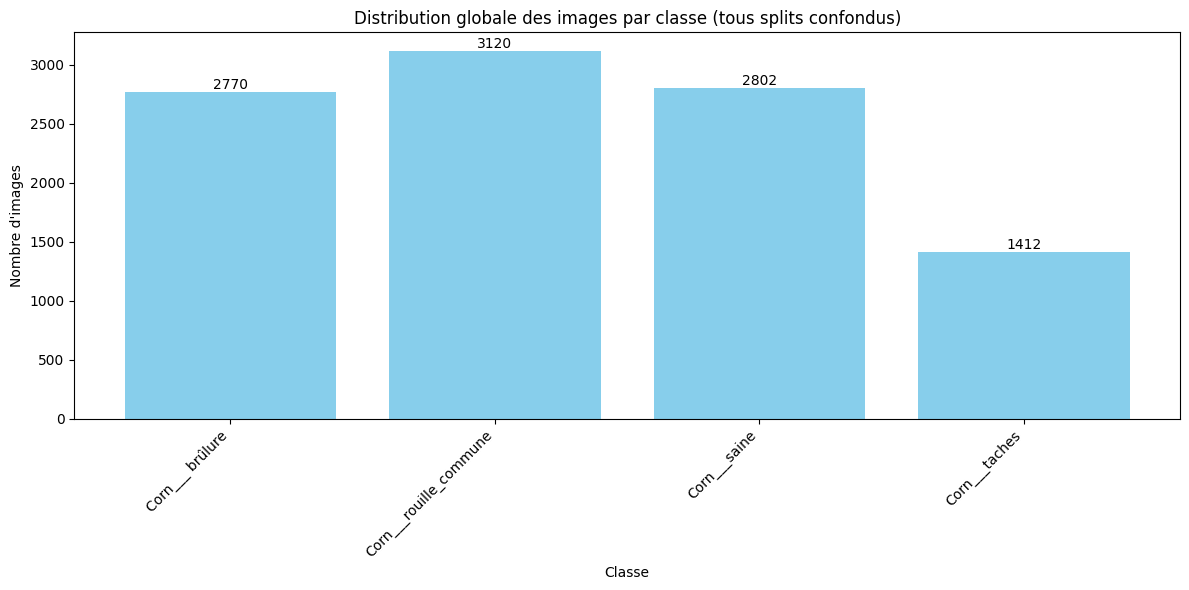

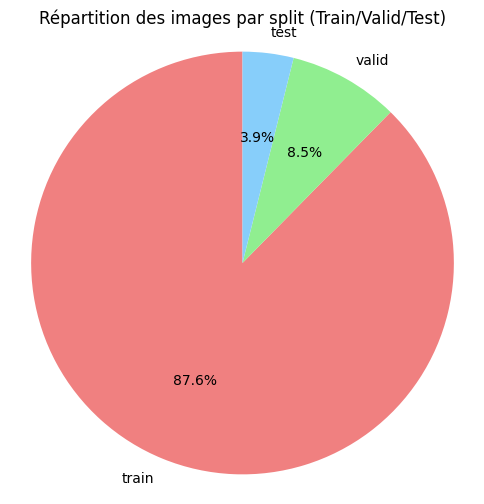

In [ ]:
import matplotlib.pyplot as plt
import numpy as np # Pour les calculs statistiques

print("Visualisation de la distribution des classes...")
print("=" * 60)

# La variable global_class_summary_from_splits contient les comptes globaux par classe
# Elle a été calculée dans la cellule 3.

if 'global_class_summary_from_splits' in locals() or 'global_class_summary_from_splits' in globals():
    global_class_summary_to_plot = global_class_summary_from_splits

    if global_class_summary_to_plot and sum(global_class_summary_to_plot.values()) > 0:
        classes = list(global_class_summary_to_plot.keys())
        counts = list(global_class_summary_to_plot.values())

        # Trier les classes et les comptes ensemble pour une meilleure visualisation
        sorted_indices = np.argsort(classes)
        sorted_classes = [classes[i] for i in sorted_indices]
        sorted_counts = [counts[i] for i in sorted_indices]

        # Créer le graphique à barres
        plt.figure(figsize=(12, 6)) # Ajustez la taille de la figure selon le nombre de classes
        bars = plt.bar(sorted_classes, sorted_counts, color='skyblue')
        plt.xlabel("Classe")
        plt.ylabel("Nombre d'images")
        plt.title("Distribution globale des images par classe (tous splits confondus)")
        plt.xticks(rotation=45, ha='right') # Rotation des étiquettes si elles sont longues
        plt.tight_layout() # Ajuster la mise en page pour éviter le chevauchement

        # Ajouter les comptes au-dessus des barres
        for bar in bars:
            yval = bar.get_height()
            plt.text(bar.get_x() + bar.get_width()/2.0, yval, int(yval), va='bottom', ha='center') # va: vertical alignment, ha: horizontal alignment


        plt.show()

    else:
        print("Aucune donnée de classe disponible pour la visualisation.")

else:
    print("Les informations du résumé global par classe ne sont pas disponibles. Exécutez la cellule 3 d'abord.")

# Optionnel: Vous pourriez aussi visualiser la répartition par split si vous le souhaitez.
# Exemple simple pour la répartition par split:
if 'split_totals' in locals() or 'split_totals' in globals():
    split_totals_to_plot = split_totals
    if split_totals_to_plot and sum(split_totals_to_plot.values()) > 0:
        splits = list(split_totals_to_plot.keys())
        counts = list(split_totals_to_plot.values())

        plt.figure(figsize=(6, 6))
        plt.pie(counts, labels=splits, autopct='%1.1f%%', startangle=90, colors=['lightcoral', 'lightgreen', 'lightskyblue'])
        plt.title("Répartition des images par split (Train/Valid/Test)")
        plt.axis('equal') # Assure que le diagramme circulaire est bien un cercle.
        plt.show()
    else:
         print("\nAucune donnée de split disponible pour la visualisation.")
else:
    print("\nLes informations des totaux par split ne sont pas disponibles.")

### 10. Préparer le dataset pour la modélisation

Cette section explore les considérations nécessaires pour préparer le dataset avant de l'utiliser pour l'entraînement d'un modèle d'apprentissage automatique, en se basant sur les résultats de l'analyse précédente.

In [ ]:
# --- Considérations pour la préparation du dataset ---

print("Considérations pour la préparation du dataset pour la modélisation...")
print("=" * 60)

# 1. Gestion du déséquilibre de classes:
# L'analyse (Cellule 8) a montré s'il existe un déséquilibre significatif.
# Si c'est le cas, des techniques comme l'augmentation de données sur les classes minoritaires,
# ou l'utilisation de pondérations de classes pendant l'entraînement seront nécessaires.
print("\n1. Gestion du déséquilibre de classes:")
if 'global_class_summary_from_splits' in locals() or 'global_class_summary_from_splits' in globals():
    if global_class_summary_from_splits and sum(global_class_summary_from_splits.values()) > 0:
        class_counts = list(global_class_summary_from_splits.values())
        min_count = np.min(class_counts)
        max_count = np.max(class_counts)
        max_min_ratio = max_count / min_count if min_count > 0 else float('inf')

        print(f"   - Ratio Max/Min des classes (global) : {max_min_ratio:.2f}")
        if max_min_ratio > 2:
            print("   - Déséquilibre détecté : Envisager l'augmentation de données ou la pondération des classes.")
        else:
            print("   - Déséquilibre modéré ou faible détecté.")
    else:
        print("   - Informations sur le déséquilibre non disponibles. Exécutez la Cellule 8.")
else:
    print("   - Informations sur le déséquilibre non disponibles. Exécutez les cellules de comptage.")


# 2. Taille des images:
# L'analyse des dimensions (Cellule 5 ou 9) a montré les tailles actuelles.
# Pour l'entraînement, les modèles nécessitent généralement une taille d'entrée fixe.
# Vous devrez décider d'une taille cible (par exemple, 224x224, 299x299) et redimensionner toutes les images.
print("\n2. Taille des images:")
if 'image_widths' in locals() and 'image_heights' in locals() and image_widths and image_heights:
    unique_widths = set(image_widths)
    unique_heights = set(image_heights)
    if len(unique_widths) == 1 and len(unique_heights) == 1:
        print(f"   - Toutes les images ont la même dimension : {unique_widths.pop()}x{unique_heights.pop()} pixels.")
        print("   - Vous devrez peut-être redimensionner à une taille d'entrée standard pour le modèle.")
    else:
        print(f"   - Les images ont des dimensions variables. Largeurs uniques: {sorted(list(unique_widths))}, Hauteurs uniques: {sorted(list(unique_heights))}")
        print("   - Vous devrez absolument redimensionner toutes les images à une taille d'entrée fixe.")
    # Suggestion de taille courante (exemple)
    suggested_target_size = (224, 224)
    print(f"   - Taille cible courante suggérée pour les modèles : {suggested_target_size}")

else:
    print("   - Informations sur les dimensions des images non disponibles. Exécutez la Cellule 5 ou 9.")


# 3. Division en train/valid/test:
# L'analyse a montré que le dataset est déjà divisé en splits (Cellule 3 ou 8).
# Vous utiliserez ces splits pour l'entraînement, la validation et les tests finaux.
print("\n3. Division en train/valid/test:")
if 'split_totals' in locals() or 'split_totals' in globals():
    if split_totals and sum(split_totals.values()) > 0:
        print("   - Le dataset est déjà divisé en splits 'train', 'valid', 'test'.")
        print("   - Vous utiliserez ces splits pour l'entraînement et l'évaluation.")
        # Afficher les proportions des splits à nouveau pour rappel
        grand_total_dataset = sum(split_totals.values())
        if grand_total_dataset > 0:
             print("   - Proportions des splits :")
             for split_name in ['train', 'valid', 'test']:
                  count = split_totals.get(split_name, 0)
                  percentage = (count / grand_total_dataset * 100) if grand_total_dataset > 0 else 0
                  print(f"     - {split_name.capitalize()} : {count} images ({percentage:.2f}%)")
        else:
             print("   - Aucune image trouvée dans les splits pour calculer les proportions.")
    else:
        print("   - Informations sur les totaux par split non disponibles. Exécutez la Cellule 3 ou 8.")
else:
    print("   - Informations sur les totaux par split non disponibles. Exécutez les cellules de comptage.")


# 4. Transformations d'images (Augmentation, Normalisation, etc.):
# Ces transformations sont appliquées pendant l'entraînement pour améliorer les performances et la robustesse du modèle.
print("\n4. Transformations d'images:")
print("   - L'augmentation de données (rotations, zooms, etc.) peut aider à augmenter la taille effective du dataset et gérer le déséquilibre.")
print("   - La normalisation des valeurs de pixels est généralement nécessaire avant de passer les images au modèle.")


print("\nCes points sont essentiels à considérer avant de passer à la construction et à l'entraînement du modèle.")

Considérations pour la préparation du dataset pour la modélisation...

1. Gestion du déséquilibre de classes:
   - Ratio Max/Min des classes (global) : 2.21
   - Déséquilibre détecté : Envisager l'augmentation de données ou la pondération des classes.

2. Taille des images:
   - Toutes les images ont la même dimension : 640x640 pixels.
   - Vous devrez peut-être redimensionner à une taille d'entrée standard pour le modèle.
   - Taille cible courante suggérée pour les modèles : (224, 224)

3. Division en train/valid/test:
   - Le dataset est déjà divisé en splits 'train', 'valid', 'test'.
   - Vous utiliserez ces splits pour l'entraînement et l'évaluation.
   - Proportions des splits :
     - Train : 8856 images (87.65%)
     - Valid : 855 images (8.46%)
     - Test : 393 images (3.89%)

4. Transformations d'images:
   - L'augmentation de données (rotations, zooms, etc.) peut aider à augmenter la taille effective du dataset et gérer le déséquilibre.
   - La normalisation des valeurs de 

### 11. Préparer l'environnement pour la modélisation

Cette cellule configure l'environnement en vérifiant la disponibilité d'un GPU et en important les bibliothèques nécessaires pour la construction et l'entraînement d'un modèle d'apprentissage automatique.

In [ ]:
# Importer les bibliothèques nécessaires
import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt # Probablement déjà importé, mais on s'assure

# Vérifier la version de TensorFlow
print("Version de TensorFlow :", tf.__version__)

# Vérifier la disponibilité d'un GPU
gpu_available = tf.config.list_physical_devices('GPU')
if gpu_available:
    print("GPU disponible :", gpu_available)
    # Configurer TensorFlow pour utiliser le GPU s'il y en a plusieurs
    try:
        tf.config.experimental.set_memory_growth(gpu_available[0], True)
    except:
        # Ignorer si la croissance de la mémoire n'est pas prise en charge
        pass
else:
    print("Aucun GPU disponible. L'entraînement s'effectuera sur le CPU.")

# Définir quelques paramètres de base (peuvent être ajustés)
IMAGE_SIZE = (224, 224) # Taille cible pour le redimensionnement des images
BATCH_SIZE = 16       # Nombre d'images par lot pour l'entraînement (Réduit de 32 à 16)
NUM_CLASSES = len(global_class_summary_from_splits) if 'global_class_summary_from_splits' in locals() or 'global_class_summary_from_splits' in globals() else 4 # Nombre de classes (essayer de le récupérer si possible)


print(f"\nTaille cible des images pour le modèle : {IMAGE_SIZE}")
print(f"Taille des lots pour l'entraînement : {BATCH_SIZE}")
print(f"Nombre de classes détectées : {NUM_CLASSES}")

# Le chemin de base du dataset et les extensions d'images sont déjà définis
# datasets_base_path = '/content/drive/MyDrive/DataSets'
# image_extensions = [...]
# La liste des images corrompues (corrupted_images) est disponible
# Les comptes par split/classe sont disponibles
# all_detected_classes est disponible

Version de TensorFlow : 2.18.0
Aucun GPU disponible. L'entraînement s'effectuera sur le CPU.

Taille cible des images pour le modèle : (224, 224)
Taille des lots pour l'entraînement : 16
Nombre de classes détectées : 4


### 12. Préparer les générateurs de données

Cette cellule va configurer les générateurs de données pour les splits d'entraînement, de validation et de test. Ces générateurs chargeront les images depuis Google Drive, les redimensionneront et appliqueront les transformations nécessaires.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os # Assurez-vous que os est importé

# Chemin du répertoire principal du dataset (défini dans la cellule 1)
# datasets_base_path = '/content/drive/MyDrive/DataSets'

# Paramètres (définis dans la cellule 11)
# IMAGE_SIZE = (224, 224)
# BATCH_SIZE = 16 # Maintenant défini à 16 dans la cellule 11
# NUM_CLASSES = ... (détecté ou défini)

# Extensions de fichiers image (définies plus tôt)
# image_extensions = ['.jpg', '.jpeg', '.png', '.gif', '.bmp', '.tiff']

# Liste des noms de classes détectées (disponible depuis la cellule 2 ou 3)
# all_detected_classes = sorted(list(global_class_summary_from_splits.keys())) if 'global_class_summary_from_splits' in locals() or 'global_class_summary_from_splits' in globals() else ['Classe1', 'Classe2', 'Classe3', 'Classe4'] # Assurez-vous que cette liste est correcte


print("Configuration des générateurs de données...")

# --- Configuration de l'augmentation de données (pour le split d'entraînement) ---
# L'augmentation de données aide à rendre le modèle plus robuste et peut atténuer le déséquilibre.
# Ajustez ces paramètres selon vos besoins et expérimentations.
train_datagen = ImageDataGenerator(
    rescale=1./255,           # Normalisation des pixels entre 0 et 1
    rotation_range=20,        # Rotation aléatoire jusqu'à 20 degrés
    width_shift_range=0.2,    # Déplacement horizontal aléatoire
    height_shift_range=0.2,   # Déplacement vertical aléatoire
    shear_range=0.2,          # Cisaillement aléatoire
    zoom_range=0.2,           # Zoom aléatoire
    horizontal_flip=True,     # Miroir horizontal aléatoire
    fill_mode='nearest'       # Stratégie pour remplir les pixels nouvellement créés
    # Si vous avez un fort déséquilibre, vous pourriez aussi envisager:
    # class_weight=... ou utiliser des techniques d'oversampling/undersampling
)

# --- Configuration pour les splits de validation et de test ---
# Pour la validation et le test, on ne fait généralement que la normalisation.
validation_test_datagen = ImageDataGenerator(rescale=1./255)


# --- Création des générateurs ---
# Utilisez flow_from_directory pour charger les images directement depuis les dossiers.

# Chemin des splits
train_dir = os.path.join(datasets_base_path, 'train')
validation_dir = os.path.join(datasets_base_path, 'valid') # Ou 'val' selon votre structure
test_dir = os.path.join(datasets_base_path, 'test')

# Assurez-vous que les noms de classes correspondent aux noms de vos dossiers de classes
# all_detected_classes doit contenir les noms exacts des dossiers de classes.
if 'all_detected_classes' not in locals() and 'all_detected_classes' not in globals():
     print("\nAttention: La variable 'all_detected_classes' n'est pas disponible.")
     print("Veuillez exécuter la cellule d'analyse de structure (Cellule 2) pour la définir.")
     # Tentative de détection simple si possible
     if 'dataset_info' in locals() or 'dataset_info' in globals():
          all_detected_classes = set()
          for info in dataset_info.values():
               all_detected_classes.update(info['classes'])
          all_detected_classes = sorted(list(all_detected_classes))
          print("Classes détectées à partir de dataset_info :", all_detected_classes)
     else:
          print("Impossible de détecter les classes automatiquement sans dataset_info.")
          all_detected_classes = [] # Initialiser vide pour éviter une erreur


if not all_detected_classes:
    print("\nErreur : Les noms de classes n'ont pas été détectés. Impossible de créer les générateurs.")
else:
    print(f"\nUtilisation des classes : {all_detected_classes}")

    try:
        train_generator = train_datagen.flow_from_directory(
            train_dir,
            target_size=IMAGE_SIZE,
            batch_size=BATCH_SIZE,
            class_mode='categorical', # Pour la classification multi-classes
            classes=all_detected_classes, # S'assurer que l'ordre des classes est cohérent
            # subset='training' # Si vous utilisez validation_split dans ImageDataGenerator
        )

        validation_generator = validation_test_datagen.flow_from_directory(
            validation_dir,
            target_size=IMAGE_SIZE,
            batch_size=BATCH_SIZE,
            class_mode='categorical',
            classes=all_detected_classes,
            # subset='validation' # Si vous utilisez validation_split dans ImageDataGenerator
        )

        test_generator = validation_test_datagen.flow_from_directory(
            test_dir,
            target_size=IMAGE_SIZE,
            batch_size=BATCH_SIZE,
            class_mode='categorical',
            classes=all_detected_classes,
        )

        print("\nGénérateurs de données créés avec succès.")
        print(f"Nombre de classes détectées par les générateurs : {train_generator.num_classes}")
        print(f"Ordre des classes dans le générateur d'entraînement : {train_generator.class_indices}")

    except Exception as e:
        print(f"\nErreur lors de la création des générateurs de données : {e}")
        print("Veuillez vérifier les chemins des répertoires (train_dir, validation_dir, test_dir) et les noms de classes.")


# Les générateurs (train_generator, validation_generator, test_generator) sont maintenant prêts à être utilisés.

Configuration des générateurs de données...

Utilisation des classes : {'Corn___taches', 'Corn___rouille_commune', 'Corn___ brûlure', 'Corn___saine'}
Found 8856 images belonging to 4 classes.
Found 855 images belonging to 4 classes.
Found 393 images belonging to 4 classes.

Générateurs de données créés avec succès.
Nombre de classes détectées par les générateurs : 4
Ordre des classes dans le générateur d'entraînement : {'Corn___taches': 0, 'Corn___rouille_commune': 1, 'Corn___ brûlure': 2, 'Corn___saine': 3}


### 13. Définir un modèle CNN simple

Cette cellule définit l'architecture d'un réseau de neurones convolutionnel (CNN) simple en utilisant l'API Séquentielle de Keras, adapté à la taille de vos images et au nombre de classes.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Les paramètres IMAGE_SIZE et NUM_CLASSES sont définis dans la cellule 11.
# IMAGE_SIZE = (224, 224)
# NUM_CLASSES = ...

print("Définition d'un modèle CNN simple...")

# Définir le modèle séquentiel
model = Sequential([
    # Première couche de convolution et de pooling
    Conv2D(32, (3, 3), activation='relu', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)), # 3 pour les canaux de couleur (RVB)
    MaxPooling2D((2, 2)),

    # Deuxième couche de convolution et de pooling
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Troisième couche de convolution et de pooling
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    # Aplatir la sortie des couches convolutionnelles
    Flatten(),

    # Couches denses (fully connected)
    Dense(512, activation='relu'),
    Dropout(0.5), # Couche de Dropout pour réduire l'overfitting

    # Couche de sortie
    Dense(NUM_CLASSES, activation='softmax') # 'softmax' pour la classification multi-classes
])

# Afficher un résumé de l'architecture du modèle
model.summary()

print("\nModèle CNN simple défini.")

Définition d'un modèle CNN simple...


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,398,148 (169.37 MB)

 Trainable params: 44,398,148 (169.37 MB)

 Non-trainable params: 0 (0.00 B)


Modèle CNN simple défini.


### 14. Compiler le modèle

Cette cellule configure le processus d'entraînement du modèle en spécifiant la fonction de perte, l'optimiseur et les métriques d'évaluation.

In [ ]:
from tensorflow.keras.optimizers import Adam

# Le modèle (model) a été défini dans la cellule précédente (13).

print("Compilation du modèle...")

# Compiler le modèle
model.compile(
    loss='categorical_crossentropy', # Fonction de perte pour classification multi-classes
    optimizer=Adam(learning_rate=0.001), # Optimiseur Adam avec un taux d'apprentissage initial
    metrics=['accuracy'] # Métrique d'évaluation (exactitude)
)

print("\nModèle compilé avec succès.")

Compilation du modèle...

Modèle compilé avec succès.


### 15. Entraîner le modèle

Cette cellule lance le processus d'entraînement du modèle en utilisant les générateurs de données pour les splits d'entraînement et de validation.

In [ ]:
# Le modèle (model) a été compilé dans la cellule précédente (14).
# Les générateurs de données (train_generator, validation_generator) ont été créés dans la cellule 12.
# Le nombre d'époques (EPOCHS) est défini ici ou peut être une variable.
TOTAL_EPOCHS = 20 # Nombre total d'époques souhaité

# Importer les callbacks nécessaires
from tensorflow.keras.callbacks import ModelCheckpoint

# Définir le chemin où sauvegarder les checkpoints
checkpoint_path = "training_checkpoints/cp-{epoch:04d}.weights.h5"
checkpoint_dir = os.path.dirname(checkpoint_path)

# Créer le répertoire si nécessaire
if not os.path.exists(checkpoint_dir):
    os.makedirs(checkpoint_dir)

# Créer un callback qui sauvegarde les poids du modèle
cp_callback = ModelCheckpoint(
    filepath=checkpoint_path,
    save_weights_only=True, # Sauvegarde uniquement les poids
    verbose=1, # Affiche un message quand un checkpoint est sauvegardé
    # period=1 # Supprimé car obsolète
)

# Vérifier s'il existe un checkpoint récent pour reprendre l'entraînement
latest_checkpoint = tf.train.latest_checkpoint(checkpoint_dir)

if latest_checkpoint:
    print(f"Chargement du dernier checkpoint : {latest_checkpoint}")
    model.load_weights(latest_checkpoint)
    # On peut aussi essayer de déterminer l'époque à partir du nom du fichier
    try:
        # Extraire le numéro d'époque du nom du fichier (ex: cp-0010.weights.h5 -> 10)
        start_epoch = int(latest_checkpoint.split('-')[1].split('.')[0])
        print(f"Reprise de l'entraînement à partir de l'époque {start_epoch + 1}")
    except:
        start_epoch = 0 # Si le nom du fichier ne peut pas être parsé
        print("Impossible de déterminer l'époque de départ à partir du nom du checkpoint. Reprise à partir de l'époque 1.")
else:
    print("Aucun checkpoint trouvé. Début de l'entraînement à partir de l'époque 1.")
    start_epoch = 0

# Définir le nombre d'époques pour cette exécution (juste une époque de plus pour obtenir l'historique)
# Si start_epoch est déjà la dernière époque, cela ne fera qu'une seule époque.
# Si start_epoch est 0, cela fera 1 époque.
EPOCHS_TO_RUN = start_epoch + 1 # Exécuter jusqu'à l'époque start_epoch + 1

# S'assurer que l'on ne dépasse pas le nombre total d'époques souhaité si on relance plusieurs fois
if EPOCHS_TO_RUN > TOTAL_EPOCHS:
    EPOCHS_TO_RUN = TOTAL_EPOCHS
    print(f"Atteint le nombre total d'époques souhaité ({TOTAL_EPOCHS}). Exécution jusqu'à l'époque {EPOCHS_TO_RUN}.")


print(f"Lancement de l'entraînement pour {EPOCHS_TO_RUN - start_epoch} époque(s) supplémentaire(s) (Total visé {TOTAL_EPOCHS} époques)...")


# Calculer les steps_per_epoch et validation_steps
# steps_per_epoch = Nombre total d'images d'entraînement / BATCH_SIZE
# validation_steps = Nombre total d'images de validation / BATCH_SIZE
# Assurez-vous que train_generator et validation_generator ont l'attribut samples ou n
if 'train_generator' in locals() or 'train_generator' in globals():
    if hasattr(train_generator, 'samples') and hasattr(validation_generator, 'samples'):
        steps_per_epoch = train_generator.samples // BATCH_SIZE
        validation_steps = validation_generator.samples // BATCH_SIZE
        # Gérer le cas où le nombre total d'images n'est pas un multiple de BATCH_SIZE
        if train_generator.samples % BATCH_SIZE != 0:
            steps_per_epoch += 1
        if validation_generator.samples % BATCH_SIZE != 0:
            validation_steps += 1
        print(f"Steps par époque : {steps_per_epoch}")
        print(f"Steps de validation : {validation_steps}")

    elif hasattr(train_generator, 'n') and hasattr(validation_generator, 'n'): # Alternative pour certaines versions/types de générateurs
        steps_per_epoch = train_generator.n // BATCH_SIZE
        validation_steps = validation_generator.n // BATCH_SIZE
        if train_generator.n % BATCH_SIZE != 0:
            steps_per_epoch += 1
        if validation_generator.n % BATCH_SIZE != 0:
            validation_steps += 1
        print(f"Steps par époque (basé sur .n) : {steps_per_epoch}")
        print(f"Steps de validation (basé sur .n) : {validation_steps}")

    else:
        print("Attention: Impossible de déterminer automatiquement steps_per_epoch et validation_steps.")
        print("Vous devrez peut-être les calculer manuellement ou laisser Keras le faire (peut être moins précis).")
        steps_per_epoch = None # Laisser Keras le calculer
        validation_steps = None # Laisser Keras le calculer
else:
    print("Erreur: Les générateurs de données (train_generator, validation_generator) ne sont pas définis. Exécutez la Cellule 12.")
    steps_per_epoch = None
    validation_steps = None


# Lancer l'entraînement seulement si les générateurs sont définis
if steps_per_epoch is not None and validation_steps is not None:
    # L'objet history stocke les informations sur l'entraînement (perte, exactitude, etc.)
    history = model.fit(
        train_generator,
        initial_epoch=start_epoch, # Spécifier l'époque de départ
        steps_per_epoch=steps_per_epoch, # Combien de lots par époque
        epochs=EPOCHS_TO_RUN, # Nombre total d'époques pour cette exécution
        validation_data=validation_generator,
        validation_steps=validation_steps, # Combien de lots de validation par époque
        # Ajouter le callback de checkpoint
        callbacks=[cp_callback]
    )

    print("\nEntraînement terminé.")

    # L'objet history est maintenant disponible pour visualiser les courbes d'entraînement.
else:
    print("\nEntraînement non lancé car les générateurs de données ne sont pas disponibles.")

Aucun checkpoint trouvé. Début de l'entraînement à partir de l'époque 1.
Lancement de l'entraînement pour 1 époque(s) supplémentaire(s) (Total visé 20 époques)...
Steps par époque : 554
Steps de validation : 54


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


554/554 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6615 - loss: 1.1230

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: saving model to training_checkpoints/cp-0001.weights.h5
554/554 ━━━━━━━━━━━━━━━━━━━━ 2008s 4s/step - accuracy: 0.6617 - loss: 1.1222 - val_accuracy: 0.8316 - val_loss: 0.4540

Entraînement terminé.


### 16. Visualiser les courbes d'entraînement

Cette cellule va tracer les courbes d'exactitude et de perte de l'entraînement et de la validation au fil des époques pour évaluer la performance du modèle et détecter un éventuel surajustement (overfitting).

Visualisation des courbes d'entraînement...


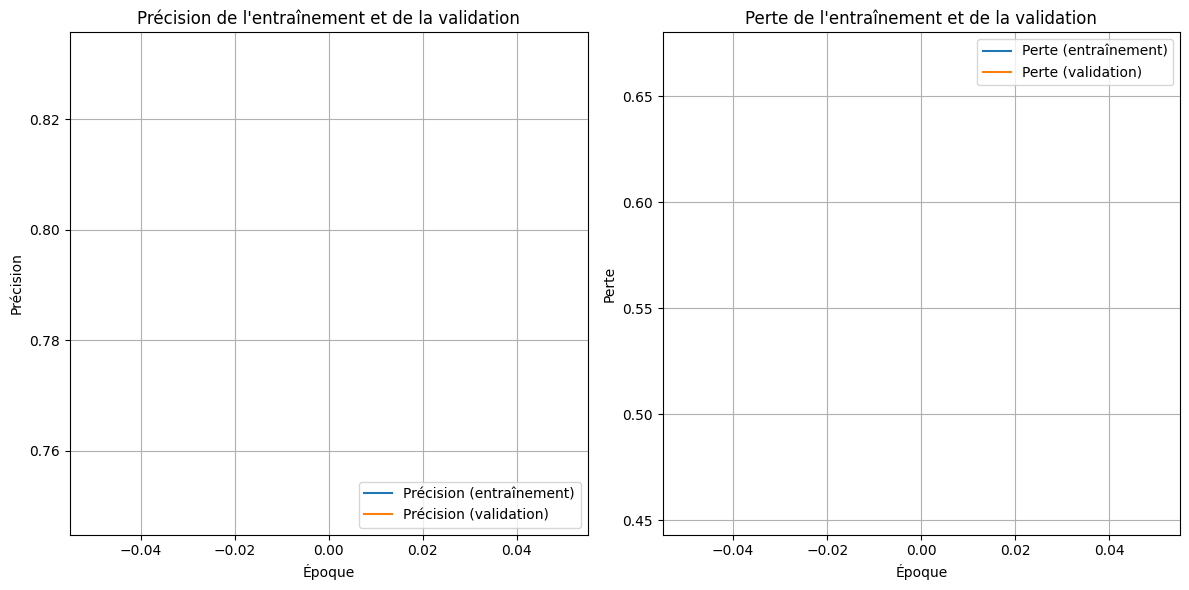

In [ ]:
import matplotlib.pyplot as plt

print("Visualisation des courbes d'entraînement...")
print("=" * 60)

# L'objet history a été généré par model.fit dans la cellule précédente (15).

if 'history' in locals() or 'history' in globals():
    # Récupérer les données de l'historique
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    # Tracer les courbes d'exactitude
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1) # 1 ligne, 2 colonnes, premier plot
    plt.plot(epochs_range, acc, label='Précision (entraînement)')
    plt.plot(epochs_range, val_acc, label='Précision (validation)')
    plt.title("Précision de l'entraînement et de la validation")
    plt.xlabel("Époque")
    plt.ylabel("Précision")
    plt.legend(loc='lower right')
    plt.grid(True)

    # Tracer les courbes de perte
    plt.subplot(1, 2, 2) # 1 ligne, 2 colonnes, deuxième plot
    plt.plot(epochs_range, loss, label='Perte (entraînement)')
    plt.plot(epochs_range, val_loss, label='Perte (validation)')
    plt.title("Perte de l'entraînement et de la validation")
    plt.xlabel("Époque")
    plt.ylabel("Perte")
    plt.legend(loc='upper right')
    plt.grid(True)

    plt.tight_layout() # Ajuster la mise en page
    plt.show()

else:
    print("L'objet 'history' n'est pas disponible. Veuillez exécuter la cellule d'entraînement (Cellule 15) d'abord.")

### 17. Évaluer le modèle sur l'ensemble de test

Cette cellule va évaluer les performances finales du modèle entraîné en utilisant l'ensemble de données de test, qui n'a pas été utilisé pendant l'entraînement ou la validation.

In [ ]:
print("Évaluation du modèle sur l'ensemble de test...")
print("=" * 60)

# Le modèle (model) a été entraîné dans la cellule 15.
# Le générateur de test (test_generator) a été créé dans la cellule 12.

if 'model' in locals() or 'model' in globals():
    if 'test_generator' in locals() or 'test_generator' in globals():
        # Calculer les test_steps
        if hasattr(test_generator, 'samples'):
            test_steps = test_generator.samples // BATCH_SIZE
            if test_generator.samples % BATCH_SIZE != 0:
                test_steps += 1
        elif hasattr(test_generator, 'n'): # Alternative
            test_steps = test_generator.n // BATCH_SIZE
            if test_generator.n % BATCH_SIZE != 0:
                test_steps += 1
        else:
            print("Attention: Impossible de déterminer automatiquement test_steps.")
            print("Vous devrez peut-être le calculer manuellement ou laisser Keras le faire.")
            test_steps = None # Laisser Keras le calculer


        # Évaluer le modèle
        # La fonction evaluate retourne la perte et les métriques spécifiées lors de la compilation.
        # Dans ce cas, elle retournera [test_loss, test_accuracy].
        test_results = model.evaluate(
            test_generator,
            steps=test_steps # Combien de lots de test
        )

        print("\nRésultats de l'évaluation sur l'ensemble de test :")
        # Afficher les résultats avec les noms des métriques
        # Assurez-vous que l'ordre correspond à model.metrics_names
        if len(test_results) == len(model.metrics_names):
            for metric_name, metric_value in zip(model.metrics_names, test_results):
                 print(f"  {metric_name.capitalize()} : {metric_value:.4f}")
        else:
            print(f"  Perte : {test_results[0]:.4f}")
            print(f"  Précision : {test_results[1]:.4f}") # Assumant que l'exactitude est la deuxième métrique

    else:
        print("Le générateur de test ('test_generator') n'est pas disponible. Veuillez exécuter la cellule 12.")

else:
    print("Le modèle ('model') n'est pas disponible. Veuillez exécuter les cellules 13 à 15.")

Évaluation du modèle sur l'ensemble de test...


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


25/25 ━━━━━━━━━━━━━━━━━━━━ 20s 782ms/step - accuracy: 0.8191 - loss: 0.4070

Résultats de l'évaluation sur l'ensemble de test :
  Loss : 0.4072
  Compile_metrics : 0.8168


### 18. Interpréter les résultats et conclure

Cette section résumera les performances du modèle basées sur les courbes d'entraînement et les résultats de l'évaluation sur l'ensemble de test.

In [ ]:
print("Interprétation des résultats et conclusion...")
print("=" * 60)

# Les résultats de l'évaluation sont dans test_results (si la cellule 17 a été exécutée)
# L'historique de l'entraînement est dans history (si la cellule 15 a été exécutée)

test_loss = None
test_accuracy = None

if 'test_results' in locals() or 'test_results' in globals():
    if len(test_results) > 1: # Assurez-vous qu'il y a au moins la perte et l'exactitude
         test_loss = test_results[0]
         test_accuracy = test_results[1] # Assumant que l'exactitude est la deuxième métrique

    if test_loss is not None and test_accuracy is not None:
        print(f"Performance sur l'ensemble de test :")
        print(f"  Perte (Test Loss) : {test_loss:.4f}")
        print(f"  Précision (Test Accuracy) : {test_accuracy:.4f}")
    else:
         print("Résultats de l'évaluation sur l'ensemble de test non disponibles ou incomplets.")
else:
    print("Résultats de l'évaluation sur l'ensemble de test non disponibles.")


print("\nAnalyse des courbes d'entraînement (basée sur l'historique) :")
if 'history' in locals() or 'history' in globals():
    # Accès aux dernières valeurs de l'entraînement et de la validation
    last_acc = history.history['accuracy'][-1]
    last_val_acc = history.history['val_accuracy'][-1]
    last_loss = history.history['loss'][-1]
    last_val_loss = history.history['val_loss'][-1]

    print(f"  Dernière époque d'entraînement :")
    print(f"    Précision (entraînement) : {last_acc:.4f}")
    print(f"    Perte (entraînement) : {last_loss:.4f}")
    print(f"  Dernière époque de validation :")
    print(f"    Précision (validation) : {last_val_acc:.4f}")
    print(f"    Perte (validation) : {last_val_loss:.4f}")

    # Interprétation simple du surajustement
    if last_acc > last_val_acc and last_loss < last_val_loss:
        print("\nObservation : Il pourrait y avoir un certain surajustement (overfitting).")
        print("  La performance sur l'entraînement est meilleure que sur la validation.")
        print("  Suggestions : Augmentation de données plus agressive, Dropout plus élevé, régularisation, ou arrêt précoce.")
    elif abs(last_acc - last_val_acc) < 0.05 and abs(last_loss - last_val_loss) < 0.1: # Exemple de seuils
        print("\nObservation : Le modèle semble bien généraliser.")
        print("  La performance sur l'entraînement et la validation est similaire.")
    else:
        print("\nObservation : Les courbes d'entraînement et de validation sont à analyser (Cellule 16).")
        print("  Vérifiez s'il y a un écart significatif ou d'autres motifs.")


else:
    print("L'historique de l'entraînement n'est pas disponible.")

print("\nConclusion générale :")
if test_accuracy is not None:
    print(f"Le modèle a atteint une précision de {test_accuracy:.2f} sur l'ensemble de test.")
    print("Cette performance doit être évaluée en fonction des objectifs du projet.")
else:
    print("Les performances finales sur l'ensemble de test n'ont pas pu être obtenues.")

print("\nProchaines étapes possibles :")
print("- Affiner le modèle (plus de couches, couches différentes, transfer learning).")
print("- Optimiser les hyperparamètres (taux d'apprentissage, taille des lots, paramètres d'augmentation).")
print("- Gérer le déséquilibre de classes si nécessaire (techniques spécifiques).")
print("- Déployer le modèle pour faire des prédictions sur de nouvelles images.")